# Construire un pipeline sans fuite de données

**Objectifs.** Inspecter des colonnes mixtes, séparer les observations avant l’ajustement, imputer et encoder dans une pipeline, et comparer deux traitements de l’échelle. Durée : 90 min.

Nous utilisons le dataset breast cancer fourni avec scikit-learn. Les variables et labels sont conservés localement ; la colonne catégorielle et les valeurs manquantes sont des transformations pédagogiques simulées.

## 1. Comprendre les lignes, colonnes et labels

`X` représente les caractéristiques disponibles au moment de la prédiction ; `y` la cible. Le dataset intégré est fourni pour l’apprentissage, pas pour tirer une conclusion clinique.

### Carte du chemin des données

Les lignes sont des observations et les colonnes des caractéristiques. Une valeur manquante signifie seulement qu'une mesure n'a pas été fournie ; la cause du manque peut dépendre du processus de collecte. Le graphique binaire ci-dessous localise les trous, sans imputer ni regarder la cible.

In [ ]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

data = load_breast_cancer(as_frame=True)
X = data.data[['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness']].copy()
y = data.target
X['radius_band'] = np.where(X['mean radius'] < 15, 'small', 'large')
rng = np.random.default_rng(42)
missing_rows = rng.choice(X.index, size=25, replace=False)
X.loc[missing_rows, 'mean texture'] = np.nan
print('X:', X.shape, '| y:', y.shape)
print(X.dtypes)
print('Taux manquant :\n', X.isna().mean().round(3))

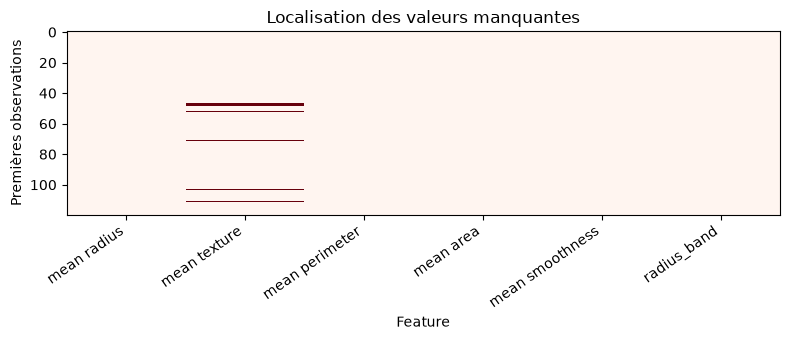

In [ ]:
import matplotlib.pyplot as plt

missing_map = X.isna().iloc[:120].to_numpy()
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.imshow(missing_map, aspect='auto', interpolation='nearest', cmap='Reds', vmin=0, vmax=1)
ax.set(xticks=range(X.shape[1]), xticklabels=X.columns, xlabel='Feature', ylabel='Premières observations', title='Localisation des valeurs manquantes')
plt.setp(ax.get_xticklabels(), rotation=35, ha='right')
plt.tight_layout(); plt.show()

Une bande rouge concentrée dans un groupe pourrait indiquer un mécanisme de collecte spécifique. Ici les trous ont été injectés au hasard pour le cours. L'imputation par médiane remplace une valeur manquante, mais ne restitue pas l'information perdue.

## 2. Séparer avant d’apprendre les transformations

Le split stratifié préserve approximativement les proportions des classes. La pipeline apprend ses statistiques uniquement quand on appelle `fit` sur `X_train`. Le jeu test reste de côté jusqu’à l’évaluation.

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42
)
print('train :', x_train.shape, '| test :', x_test.shape)
print('proportion classe 1 train/test :', round(y_train.mean(), 3), round(y_test.mean(), 3))

## 3. Expliquer les étapes du preprocessing

Les valeurs numériques sont imputées par leur médiane train puis standardisées. La catégorie est imputée par le mode train et transformée en colonnes binaires. L’encodeur ignore une catégorie jamais vue au fit plutôt que d’échouer.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

numeric_columns = ['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness']
categorical_columns = ['radius_band']
preprocess = ColumnTransformer([
    ('numeric', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), numeric_columns),
    ('category', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('one_hot', OneHotEncoder(handle_unknown='ignore'))]), categorical_columns),
])
pipeline = Pipeline([('preprocess', preprocess), ('classifier', LogisticRegression(max_iter=2_000))])
pipeline.fit(x_train, y_train)
print('Accuracy train (optimiste) :', round(accuracy_score(y_train, pipeline.predict(x_train)), 3))

### Schéma — où la pipeline apprend-elle ?

Lire les flèches de gauche à droite : la ligne supérieure ajuste les transformations numériques et catégorielles puis le classifieur **sur le train seulement**. Les flèches pointillées transportent les paramètres appris vers la ligne inférieure ; la prédiction réutilise ces paramètres pour la validation et le test, sans recalculer de médiane, d'échelle ni de catégories. La cible de validation sert à comparer des choix, celle du test à l'évaluation finale.

**Limite :** le dessin réduit les chemins internes du transformateur de colonnes et ne représente pas les séparations temporelles ou par groupe. En pratique, le test reste scellé jusqu'au choix final du modèle.

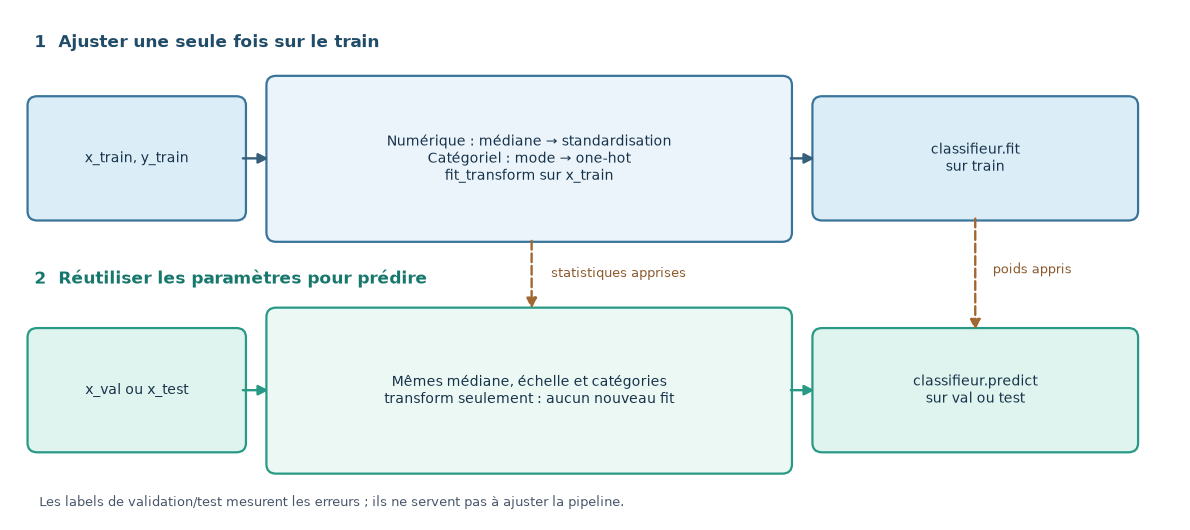

In [ ]:
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(12, 5.4))
ax.set(xlim=(0, 12), ylim=(0, 5.5))
ax.axis('off')
fig.patch.set_facecolor('white')

def pipeline_box(x, y, width, height, label, fill, border):
    shape = FancyBboxPatch((x, y), width, height,
                           boxstyle='round,pad=0.12,rounding_size=0.1',
                           linewidth=1.6, edgecolor=border, facecolor=fill)
    ax.add_patch(shape)
    ax.text(x + width / 2, y + height / 2, label,
            ha='center', va='center', fontsize=10, color='#17324a')

def pipeline_arrow(start, end, color='#355f7b', dashed=False):
    ax.add_patch(FancyArrowPatch(start, end, arrowstyle='-|>', mutation_scale=15,
                                 linewidth=1.7, color=color,
                                 linestyle='--' if dashed else '-'))

ax.text(0.25, 5.1, '1  Ajuster une seule fois sur le train',
        fontsize=12, weight='bold', color='#214c68')
pipeline_box(0.3, 3.35, 2.0, 1.1, 'x_train, y_train', '#dbeef8', '#39749b')
pipeline_box(2.75, 3.12, 5.15, 1.55,
             'Num\u00e9rique : m\u00e9diane \u2192 standardisation\nCat\u00e9goriel : mode \u2192 one-hot\nfit_transform sur x_train',
             '#eaf4fa', '#39749b')
pipeline_box(8.35, 3.35, 3.1, 1.1, 'classifieur.fit\nsur train', '#dbeef8', '#39749b')
pipeline_arrow((2.36, 3.9), (2.68, 3.9))
pipeline_arrow((7.98, 3.9), (8.28, 3.9))

ax.text(0.25, 2.55, '2  R\u00e9utiliser les param\u00e8tres pour pr\u00e9dire',
        fontsize=12, weight='bold', color='#18776d')
pipeline_box(0.3, 0.85, 2.0, 1.1, 'x_val ou x_test', '#dff4ee', '#279985')
pipeline_box(2.75, 0.62, 5.15, 1.55,
             'M\u00eames m\u00e9diane, \u00e9chelle et cat\u00e9gories\ntransform seulement : aucun nouveau fit',
             '#ebf8f3', '#279985')
pipeline_box(8.35, 0.85, 3.1, 1.1, 'classifieur.predict\nsur val ou test',
             '#dff4ee', '#279985')
pipeline_arrow((2.36, 1.4), (2.68, 1.4), color='#279985')
pipeline_arrow((7.98, 1.4), (8.28, 1.4), color='#279985')
pipeline_arrow((5.35, 3.04), (5.35, 2.25), color='#a06830', dashed=True)
pipeline_arrow((9.9, 3.28), (9.9, 2.02), color='#a06830', dashed=True)
ax.text(5.55, 2.62, 'statistiques apprises', fontsize=9, color='#8b592c')
ax.text(10.08, 2.66, 'poids appris', fontsize=9, color='#8b592c')
ax.text(0.3, 0.15,
        'Les labels de validation/test mesurent les erreurs ; ils ne servent pas \u00e0 ajuster la pipeline.',
        fontsize=9.5, color='#475569')
plt.tight_layout()
plt.show()

## 4. Où se cacherait une fuite ?

Si une médiane est calculée sur toutes les lignes avant le split, une statistique du test influence le modèle. Le petit exemple ci-dessous compare les médianes ; les valeurs test sont volontairement décalées pour rendre le problème visible. Le pipeline ci-dessus évite cette fuite en apprenant l’imputeur sur train.

In [ ]:
demo = pd.DataFrame({'value': [1.0, 2.0, 3.0, 4.0, 100.0, 120.0]})
train_demo, test_demo = demo.iloc[:4], demo.iloc[4:]
print('Médiane train :', train_demo['value'].median())
print('Médiane calculée illégalement sur train + test :', demo['value'].median())
print('Médiane test :', test_demo['value'].median())

### Le décalage du test, rendu visible

Sur `train=[1,2,3,4]`, la médiane vaut 2,5. Ajouter deux observations test très grandes change la médiane globale à 3,5. Ce décalage paraît petit, mais la règle est générale : un paramètre de preprocessing doit être appris dans les mêmes conditions que le modèle.

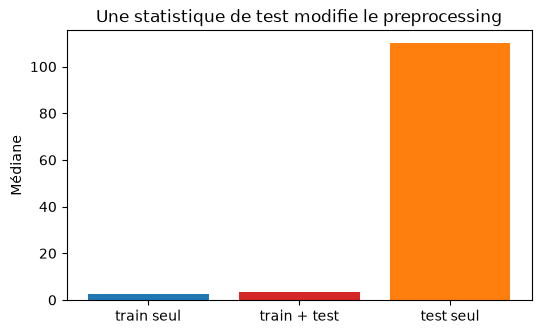

In [ ]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(['train seul', 'train + test', 'test seul'], [demo.iloc[:4]['value'].median(), demo['value'].median(), demo.iloc[4:]['value'].median()], color=['tab:blue', 'tab:red', 'tab:orange'])
ax.set(ylabel='Médiane', title='Une statistique de test modifie le preprocessing')
plt.show()

## 5. Expérience : l’échelle compte-t-elle ?

La régression logistique régularisée compare des coefficients et peut être sensible à l’échelle. Le même train/test et la même valeur de `C` sont utilisés ; seul le scaling change.

La comparaison de deux préparations utilise ici une **validation extraite du train**. Après le choix, on ajuste le candidat sur tout le train et on consulte le test une fois. Comparer les variantes directement sur le test ferait de ce jeu un outil de sélection et rendrait son score final optimiste. Une seule séparation reste fragile ; une validation croisée de la pipeline complète est préférable pour un choix important.

In [ ]:
from sklearn.pipeline import make_pipeline

x_dev, x_val, y_dev, y_val = train_test_split(
    x_train[numeric_columns], y_train, test_size=0.25, stratify=y_train, random_state=42
)
scaled_model = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), LogisticRegression(max_iter=2_000))
unscaled_model = make_pipeline(SimpleImputer(strategy='median'), LogisticRegression(max_iter=2_000))
validation_scores = {}
for name, model in [('avec StandardScaler', scaled_model), ('sans scaler', unscaled_model)]:
    model.fit(x_dev, y_dev)
    validation_scores[name] = accuracy_score(y_val, model.predict(x_val))
    print(name, 'accuracy validation :', round(validation_scores[name], 3))
selected_name = max(validation_scores, key=validation_scores.get)
selected_model = scaled_model if selected_name == 'avec StandardScaler' else unscaled_model
selected_model.fit(x_train[numeric_columns], y_train)
print('Choix sur validation :', selected_name)
print('Accuracy du test final :', round(accuracy_score(y_test, selected_model.predict(x_test[numeric_columns])), 3))

## 6. Conclusions, limites et suite

Un score n’est pas suffisant : on inspectera aussi les classes, les faux positifs/faux négatifs, le split et la stabilité en validation croisée. Le dataset a des observations apparentées et ne remplace pas une étude clinique. La catégorie `radius_band` est dérivée d’une feature et n’apporte pas d’information indépendante.

**À retenir :** split d’abord ; fit des imputers/scalers/encoders ensuite, uniquement via la pipeline sur train ; test une seule fois pour le rapport final. Les choix de données manquantes, outliers et variables temporelles nécessitent une justification métier.

## Exercices

Ecrivez une pipeline avec un seuil de catégorie différent et mesurez les changements ; comparez imputation moyenne et médiane ; vérifiez que les catégories inconnues ne font pas échouer la prédiction. [`03_preprocessing.ipynb`](../../exercises/intermediate/03_preprocessing.ipynb).